# Step-by-step Kalman Filter

## Core idea
We want to know the **state** of a system (e.g., position and velocity of a moving object), but we only have **noisy measurements** of part of the state (only the position).

The Kalman filter combines two sources of information:

1. A **model** of how the system evolves → the *prediction*.
2. The noisy **measurements** → the *correction*.

It weights them by their uncertainty: it trusts more whoever has less. That weighting is the **Kalman gain** ($K$).



## Symbol glossary

| Symbol | Meaning |
|---|---|
| $x$ | estimated state vector: `[position, velocity]` |
| $P$ | state covariance: uncertainty of the estimate |
| $F$ | transition matrix: how the state evolves in one step |
| $G$ | how random acceleration affects the state |
| $H$ | observation matrix: which part of the state we measure |
| $Q$ | process noise covariance (model uncertainty) |
| $R$ | measurement noise covariance (sensor uncertainty) |
| $z$ | measurement |
| $y$ | innovation: measurement − prediction |
| $S$ | innovation covariance |
| $K$ | Kalman gain |

In [1]:
import numpy as np                 
import matplotlib.pyplot as plt    

rng = np.random.default_rng(42)    
np.set_printoptions(precision=3, suppress=True)  

---
## Part 1. Synthetic data generation

**Scenario:** an object moves in a straight line with *almost* constant velocity. Small random accelerations (wind, friction…) perturb it. A sensor measures **only the position**, with heavy noise.

- State: $x = [\text{position},\ \text{velocity}]^\top$ (velocity is **not** measured)
- Dynamics: $\text{pos}_k = \text{pos}_{k-1} + dt\cdot\text{vel}_{k-1}$ and $\text{vel}_k = \text{vel}_{k-1} + \text{random acceleration}$

In [2]:
# ---------- Simulation parameters ----------
N = 100          # number of time steps (how many measurements we will have)
DT = 1.0         # elapsed time between two consecutive steps
SIGMA_A = 0.2    # std. dev. of random acceleration (PROCESS noise: how much the object deviates from the model)
SIGMA_Z = 5.0    # std. dev. of sensor noise (MEASUREMENT noise)
x0_real = np.array([0.0, 1.0])   # true initial state: [position = 0, velocity = 1]

# ---------- Model matrices ----------
F = np.array([[1.0, DT],         # F: transition matrix. Row 1: pos_new = pos + DT*vel
              [0.0, 1.0]])       #                          Row 2: vel_new = vel (constant velocity)

G = np.array([[0.5 * DT**2],     # G: effect of an acceleration 'a' on the state.
              [DT]])             #    Position changes by 0.5*a*DT², velocity changes by a*DT

H = np.array([[1.0, 0.0]])       # H: observation matrix. We measure only position (1st component)

Q = SIGMA_A**2 * (G @ G.T)       # Q: process noise covariance (2x2), built from G
R = np.array([[SIGMA_Z**2]])     # R: measurement noise covariance (1x1, single measurement)

# ---------- Simulation of the TRUE trajectory (hidden from the filter) ----------
x_real = np.zeros((N, 2))        # x_real: true trajectory; row k = [position_k, velocity_k]
x_real[0] = x0_real              # initial condition

for k in range(1, N):            # k: time-step index
    a = rng.normal(0.0, SIGMA_A)                       # a: random acceleration at this step
    x_real[k] = F @ x_real[k - 1] + (G * a).ravel()    # advance the true state by one step

# ---------- Noisy measurements (the ONLY thing the filter sees) ----------
noise_z = rng.normal(0.0, SIGMA_Z, size=N)   # noise_z: random sensor error at each step
z = (x_real[:, 0] + noise_z).reshape(-1, 1)  # z: measurements = true position + noise (N x 1 column)

rmse_z = np.sqrt(np.mean((z[:, 0] - x_real[:, 0])**2))   # rmse_z: root mean squared error of the raw measurement
print(f"Steps: {N} | dt = {DT} | sigma_a = {SIGMA_A} | sigma_z = {SIGMA_Z}")
print(f"RMSE of raw measurement vs. true position: {rmse_z:.3f}")

Steps: 100 | dt = 1.0 | sigma_a = 0.2 | sigma_z = 5.0
RMSE of raw measurement vs. true position: 4.894


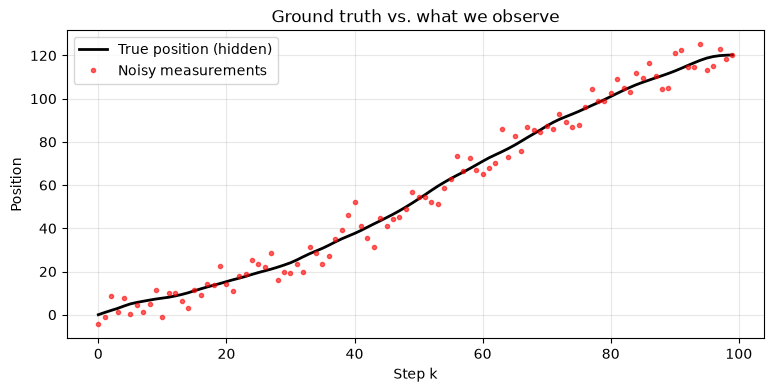

In [3]:
plt.figure(figsize=(9, 4))
plt.plot(x_real[:, 0], "k-", lw=2, label="True position (hidden)")
plt.plot(z[:, 0], "r.", alpha=0.6, label="Noisy measurements")
plt.title("Ground truth vs. what we observe")
plt.xlabel("Step k"); plt.ylabel("Position")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

---
## Part 2. A single *predict → update* cycle, broken down

Before running the filter over the whole series, let's look at **one** cycle with all its numbers.

First we define the **initial belief**: what we know before seeing data, and with how much uncertainty.

In [4]:
# ---------- Initial belief ----------
x0 = np.array([[z[0, 0]],        # x0: assumed initial state (2x1 column).
               [0.0]])           #     position = first measurement; velocity = 0 (we know nothing)

P0 = np.diag([SIGMA_Z**2,        # P0: initial uncertainty (2x2). Position: as uncertain as the sensor.
              10.0**2])          #     Velocity: highly uncertain (±10), because we don't know it

x_demo = x0.copy()               # x_demo: copy of the state for this single-step demo
P_demo = P0.copy()               # P_demo: copy of the covariance for the demo

print("Initial belief")
print("  state x         =", x_demo.ravel(), "  (position, velocity)")
print("  std. dev.       =", np.sqrt(np.diag(P_demo)))

Initial belief
  state x         = [-4.527  0.   ]   (position, velocity)
  std. dev.       = [ 5. 10.]


### Step 1: PREDICT
We project the belief one instant forward using the model. The mean advances with $F$ and the uncertainty **grows** (we add $Q$): the model is not perfect.

In [5]:
x_pred = F @ x_demo                  # x_pred: predicted state (a priori), x⁻ = F x
P_pred = F @ P_demo @ F.T + Q        # P_pred: predicted covariance (a priori), P⁻ = F P Fᵀ + Q

print("Predicted state x⁻      =", x_pred.ravel())
print("Std. dev. after predict =", np.sqrt(np.diag(P_pred)), "  <- uncertainty grew")

Predicted state x⁻      = [-4.527  0.   ]
Std. dev. after predict = [11.181 10.002]   <- uncertainty grew


### Step 2: UPDATE
The measurement $z_1$ arrives. We compare it with what we expected to see and correct according to the gain $K$.

In [6]:
z1 = z[1].reshape(-1, 1)             # z1: measurement at time k=1 (1x1 column)

z_pred = H @ x_pred                  # z_pred: measurement we EXPECTED to see according to the prediction
y = z1 - z_pred                      # y: innovation = actual measurement - expected measurement ("the surprise")
S = H @ P_pred @ H.T + R             # S: innovation covariance
K = P_pred @ H.T @ np.linalg.inv(S)  # K: Kalman gain (2x1). How much we trust the measurement: if K is close to 0 we trust the model, not the measurement,
                                        # if K is close to 1, we trust the measurement, not the model
                                        # Corrected State = Prediction + K × (Measurement − Prediction)

x_post = x_pred + K @ y              # x_post: corrected state (a posteriori)

I2 = np.eye(2)                       # I2: 2x2 identity matrix
I_KH = I2 - K @ H                    # I_KH: (I - K H), auxiliary factor
P_post = I_KH @ P_pred @ I_KH.T + K @ R @ K.T   # P_post: corrected covariance (Joseph form, numerically stable)

print(f"Measurement z          = {z1.item():.3f}")
print(f"Predicted z            = {z_pred.item():.3f}")
print(f"Innovation y           = {y.item():.3f}   (measurement - prediction)")
print(f"Innovation cov. S      = {S.item():.3f}")
print(f"Gain K                 = {K.ravel()}")
print("   K[0]: how much of the innovation is attributed to POSITION")
print("   K[1]: how much to VELOCITY (we don't measure it, but position and velocity")
print("         are correlated in P, so it gets corrected too)")
print(f"Posterior state x      = {x_post.ravel()}")
print("Posterior std. dev.    =", np.sqrt(np.diag(P_post)), "  <- uncertainty shrank")

Measurement z          = -0.860
Predicted z            = -4.527
Innovation y           = 3.667   (measurement - prediction)
Innovation cov. S      = 150.010
Gain K                 = [0.833 0.667]
   K[0]: how much of the innovation is attributed to POSITION
   K[1]: how much to VELOCITY (we don't measure it, but position and velocity
         are correlated in P, so it gets corrected too)
Posterior state x      = [-1.471  2.445]
Posterior std. dev.    = [4.564 5.775]   <- uncertainty shrank


---
## Part 3. Applying the filter to the whole series

We repeat the cycle at each time $k$ and store the history to analyze the results.

In [7]:
x = x0.copy()                        # x: current estimated state (2x1). Updated at each step
P = P0.copy()                        # P: current covariance (2x2). Updated at each step

x_post_hist = np.zeros((N, 2))       # x_post_hist: [pos, vel] estimate after correction, at each k
P_post_hist = np.zeros((N, 2, 2))    # P_post_hist: posterior covariance at each k
K_hist = np.zeros((N, 2))            # K_hist: Kalman gain at each k
innov = np.zeros(N)                  # innov: innovation y at each k
S_hist = np.zeros(N)                 # S_hist: innovation covariance S at each k

for k in range(N):                   # k: time-step index
    # ----- PREDICT (at k=0 the initial belief is already a priori) -----
    if k > 0:
        x = F @ x                    # x⁻ = F x
        P = F @ P @ F.T + Q          # P⁻ = F P Fᵀ + Q

    # ----- UPDATE -----
    zk = z[k].reshape(-1, 1)         # zk: measurement at time k (1x1)
    yk = zk - H @ x                  # yk: innovation
    Sk = H @ P @ H.T + R             # Sk: innovation covariance
    Kk = P @ H.T @ np.linalg.inv(Sk) # Kk: Kalman gain

    x = x + Kk @ yk                  # state correction
    I_KHk = np.eye(2) - Kk @ H       # I_KHk: (I - K H) at this step
    P = I_KHk @ P @ I_KHk.T + Kk @ R @ Kk.T   # covariance correction (Joseph form)

    # ----- Store history -----
    x_post_hist[k] = x.ravel()
    P_post_hist[k] = P
    K_hist[k] = Kk.ravel()
    innov[k] = yk.item()
    S_hist[k] = Sk.item()

print("Filter applied to", N, "measurements.")

Filter applied to 100 measurements.


---
## Part 4. Results and diagnostics

**Error metrics** and three **calibration diagnostics**:

- **±2σ coverage:** if the filter is well calibrated, the true value falls within ±2σ ≈ 95% of the time.
- **NIS** (innovation² / S): should average ≈ 1 (dimension of $z$).
- **Normalized innovations** ($y/\sqrt{S}$): should look like white noise $\mathcal{N}(0,1)$.

In [8]:
sd_pos = np.sqrt(P_post_hist[:, 0, 0])   # sd_pos: std. dev. of the estimated position at each k
sd_vel = np.sqrt(P_post_hist[:, 1, 1])   # sd_vel: std. dev. of the estimated velocity at each k
burn = 10                                 # burn: initial steps discarded (filter transient)

rmse_kf_pos = np.sqrt(np.mean((x_post_hist[:, 0] - x_real[:, 0])**2))   # position error of the filter
rmse_kf_vel = np.sqrt(np.mean((x_post_hist[:, 1] - x_real[:, 1])**2))   # velocity error of the filter

print("=== Errors (RMSE) ===")
print(f"Position  (raw measurement) : {rmse_z:.3f}")
print(f"Position  (Kalman)          : {rmse_kf_pos:.3f}")
print(f"Velocity  (Kalman)          : {rmse_kf_vel:.3f}   <- never measured!")

# --- Diagnostic 1: ±2σ coverage ---
inside = np.abs(x_post_hist[burn:, 0] - x_real[burn:, 0]) <= 2 * sd_pos[burn:]   # inside: True if the true value falls within ±2σ
print("\n=== Calibration diagnostics ===")
print(f"±2σ coverage of true position: {100 * inside.mean():.1f} %  (expected ≈ 95 %)")

# --- Diagnostic 2: NIS ---
nis = innov**2 / S_hist                  # nis: normalized innovation error at each k
print(f"Mean NIS: {nis[burn:].mean():.2f}  (expected ≈ 1.0)")

# --- Diagnostic 3: normalized innovations ---
innov_norm = innov / np.sqrt(S_hist)     # innov_norm: innovation divided by its expected std. dev.
print(f"Normalized innovations: mean = {innov_norm[burn:].mean():.2f}, "
      f"std. = {innov_norm[burn:].std():.2f}  (expected ≈ 0 and 1)")

=== Errors (RMSE) ===
Position  (raw measurement) : 4.894
Position  (Kalman)          : 2.224
Velocity  (Kalman)          : 0.698   <- never measured!

=== Calibration diagnostics ===
±2σ coverage of true position: 98.9 %  (expected ≈ 95 %)
Mean NIS: 0.99  (expected ≈ 1.0)
Normalized innovations: mean = -0.01, std. = 1.00  (expected ≈ 0 and 1)


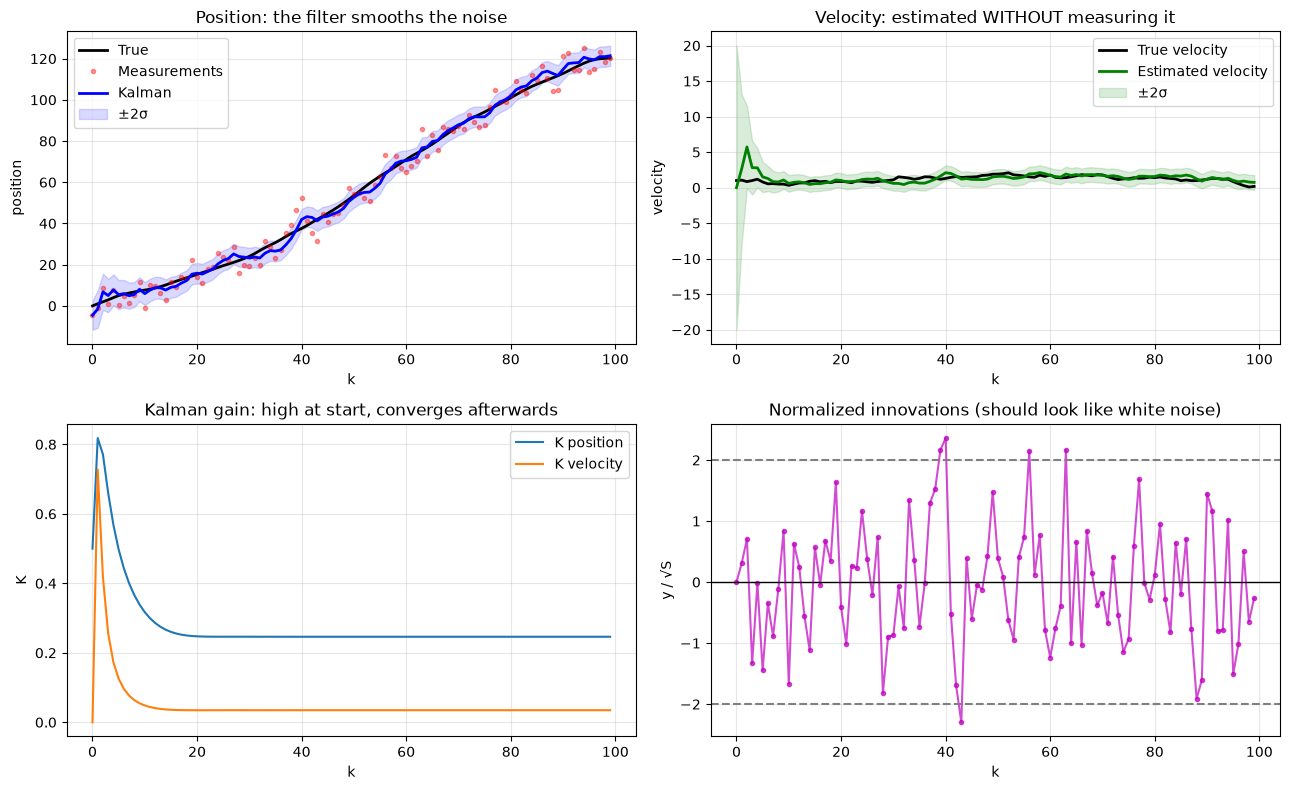

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(13, 8))   # fig, axs: figure and its 4 panels

# Panel 1: position
axs[0, 0].plot(x_real[:, 0], "k-", lw=2, label="True")
axs[0, 0].plot(z[:, 0], "r.", alpha=0.4, label="Measurements")
axs[0, 0].plot(x_post_hist[:, 0], "b-", lw=2, label="Kalman")
axs[0, 0].fill_between(range(N), x_post_hist[:, 0] - 2 * sd_pos,
                       x_post_hist[:, 0] + 2 * sd_pos, color="b", alpha=0.15, label="±2σ")
axs[0, 0].set(title="Position: the filter smooths the noise", xlabel="k", ylabel="position")
axs[0, 0].legend(); axs[0, 0].grid(alpha=0.3)

# Panel 2: velocity (never measured)
axs[0, 1].plot(x_real[:, 1], "k-", lw=2, label="True velocity")
axs[0, 1].plot(x_post_hist[:, 1], "g-", lw=2, label="Estimated velocity")
axs[0, 1].fill_between(range(N), x_post_hist[:, 1] - 2 * sd_vel,
                       x_post_hist[:, 1] + 2 * sd_vel, color="g", alpha=0.15, label="±2σ")
axs[0, 1].set(title="Velocity: estimated WITHOUT measuring it", xlabel="k", ylabel="velocity")
axs[0, 1].legend(); axs[0, 1].grid(alpha=0.3)

# Panel 3: Kalman gain
axs[1, 0].plot(K_hist[:, 0], label="K position")
axs[1, 0].plot(K_hist[:, 1], label="K velocity")
axs[1, 0].set(title="Kalman gain: high at start, converges afterwards", xlabel="k", ylabel="K")
axs[1, 0].legend(); axs[1, 0].grid(alpha=0.3)

# Panel 4: normalized innovations
axs[1, 1].plot(innov_norm, "m.-", alpha=0.7)
axs[1, 1].axhline(0, color="k", lw=1)
axs[1, 1].axhline(2, color="gray", ls="--"); axs[1, 1].axhline(-2, color="gray", ls="--")
axs[1, 1].set(title="Normalized innovations (should look like white noise)", xlabel="k", ylabel="y / √S")
axs[1, 1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

### Conclusion
The optimal filter is **not** the one that "smooths the most", but the one that best reflects the true uncertainty of the model ($Q$) and the sensor ($R$).
